### Dunnhumby Household Segmentation — Modeling

This notebook compares K-Means, Agglomerative Clustering, Gaussian Mixture Models, and DBSCAN to group households based on shopping behavior. K-Means is carried forward as the leading model because it gave the best balance of separation, full household coverage, and usable cluster structure, while labels from all four models are saved for further comparison.<br>
Demographics are not used to create the clusters. They will be added later to help describe the households within each shopping-based segment.

#### Import libraries
The libraries used here cover data handling, visualization, clustering, evaluation, and model export.

In [1]:
# Core analysis libraries
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Improve plot styling
sns.set()

# Show all columns during EDA
pd.set_option('display.max_columns', None)

# Display all dataframes generated within a cell
from IPython.display import display

In [2]:
# File path locations
from pathlib import Path

# File paths
PROJECT_ROOT = Path.cwd().resolve().parent
CLEAN_DATA_DIR = PROJECT_ROOT / "data/clean_data"
RAW_DATA_DIR = PROJECT_ROOT / "data/raw_data"
MODELS_DIR = PROJECT_ROOT / "models"
SRC_DIR = PROJECT_ROOT / "src"
DEPLOYMENT_DIR = PROJECT_ROOT / "deployment"

#### Import data
The processed household-level dataset contains 2,500 households with no missing values. The clustering features have already been transformed and scaled in the feature-engineering notebook.

In [3]:
# Import data and show first five rows
hh_shopping = pd.read_parquet(CLEAN_DATA_DIR / "03_model_features_processed.parquet")
hh_shopping.head()

,household_key,num_trips,recency_days,avg_days_between_trips,log10_avg_basket_size,log10_avg_basket_value,log10_total_spend
0,1,-0.212662,-0.327726,-0.238872,-0.728661,1.070089,3.636504
1,2,-0.567192,0.277581,-0.091021,-0.829319,0.819677,3.291000
2,3,-0.549898,-0.279938,-0.091021,0.186502,1.263775,3.423772
3,4,-0.696898,0.930675,0.059728,-0.996579,0.680335,3.079221
4,5,-0.610427,-0.279938,-0.004051,-1.322641,-0.538272,2.891571


In [4]:
# Number of rows, columns
hh_shopping.shape

(2500, 7)

In [5]:
# Data types and nulls
hh_shopping_types_null_counts = pd.DataFrame()
hh_shopping_types_null_counts["Data Type"] = hh_shopping.dtypes
hh_shopping_types_null_counts["Count of Nulls"] = hh_shopping.isna().sum()
hh_shopping_types_null_counts

,Data Type,Count of Nulls
household_key,int64,0
num_trips,float64,0
recency_days,float64,0
avg_days_between_trips,float64,0
log10_avg_basket_size,float64,0
log10_avg_basket_value,float64,0
log10_total_spend,float64,0


#### Features
The models use shopping frequency, recency, time between trips, average basket size, and average basket value. Household ID is excluded because it is only an identifier, while total spend is saved for later cluster profiling.

In [6]:
model_feature_names = [
    "num_trips", 
    "recency_days", 
    "avg_days_between_trips", 
    "log10_avg_basket_size",
    "log10_avg_basket_value"
]

X_scaled = hh_shopping[model_feature_names].copy()

#### Metrics for modeling comparison
Silhouette score is the main comparison metric, with higher values showing stronger cluster separation. Davies–Bouldin is better when lower, while Calinski–Harabasz is better when higher.

In [7]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

#### K-Means
K-Means serves as the main baseline because it creates clear, mutually exclusive household groups and is easy to explain. The elbow curve suggested either five or six clusters, so both were checked before moving forward. Only the six-cluster model was used.

In [8]:
# Import library
from sklearn.cluster import KMeans

In [9]:
# Use elbow method to determine ideal number of clusters
wcss = []
kmeans_range = range(1,11)

for k in kmeans_range:
    kmeans = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

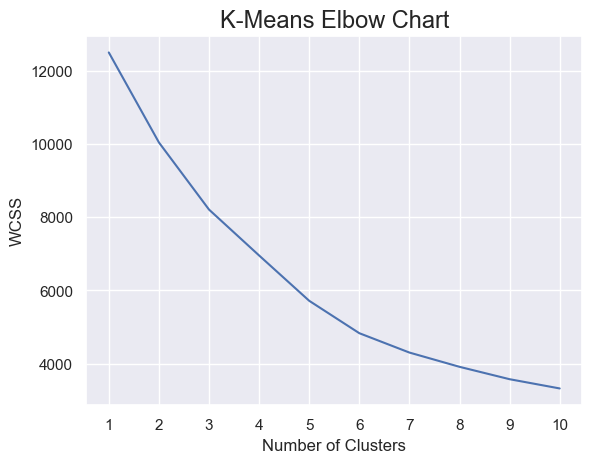

In [10]:
# Plot elbow curve
plt.plot(kmeans_range, wcss)
plt.xticks(kmeans_range)
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("K-Means Elbow Chart", fontsize=17)
plt.show()

The curve begins to level off around five to six clusters, although there is no sharp elbow. This suggests the shopping behaviors change gradually rather than forming completely separate natural groups.

In [11]:
# Re-run KMeans with 6 clusters
kmeans_model = KMeans(
    n_clusters=6,
    n_init=10,
    random_state=42
)

kmeans_labels = kmeans_model.fit_predict(X_scaled)

The five- and six-cluster versions produced similar results, and both included a few small groups. Six clusters were retained for profiling because they may represent meaningful niche or high-value shopping behaviors rather than groups that should be removed immediately.

In [12]:
# Calculate silhouette, DB Score and CH Score
kmeans_silhouette = silhouette_score(X_scaled, kmeans_labels).round(3)
kmeans_db_score = davies_bouldin_score(X_scaled, kmeans_labels).round(3)
kmeans_ch_score = calinski_harabasz_score(X_scaled, kmeans_labels).round(3)

print("KMeans silhouette =", kmeans_silhouette)
print("KMeans DB Score =", kmeans_db_score)
print("KMeans CH Score =", kmeans_ch_score)

KMeans silhouette = 0.286
KMeans DB Score = 0.962
KMeans CH Score = 791.571


#### Agglomerative Clustering
Agglomerative clustering was run with six clusters for a consistent comparison with K-Means. Its weaker scores and uneven cluster sizes suggest that it separates these households less effectively.

In [13]:
# Import library
from sklearn.cluster import AgglomerativeClustering

In [14]:
agg_model = AgglomerativeClustering(
    n_clusters=6,
    linkage="ward"
)

agg_model_labels = agg_model.fit_predict(X_scaled)

In [15]:
# Calculate silhouette, DB Score and CH Score
agg_silhouette = silhouette_score(X_scaled, agg_model_labels).round(3)
agg_db_score = davies_bouldin_score(X_scaled, agg_model_labels).round(3)
agg_ch_score = calinski_harabasz_score(X_scaled, agg_model_labels).round(3)

print("AgglomerativeClustering silhouette =", agg_silhouette)
print("AgglomerativeClustering DB Score =", agg_db_score)
print("AgglomerativeClustering CH Score =", agg_ch_score)

AgglomerativeClustering silhouette = 0.244
AgglomerativeClustering DB Score = 1.024
AgglomerativeClustering CH Score = 592.657


#### GMM (Gaussian Mixture Model)
GMM was also run with six groups and allows for more flexible cluster shapes than K-Means. It produced more balanced group sizes, but its low silhouette score and high DB score point to considerable overlap between them.

In [16]:
# Import library
from sklearn.mixture import GaussianMixture

In [17]:
gmm = GaussianMixture(
    n_components=6,
    random_state=42,
    n_init=10
)

gmm_labels = gmm.fit_predict(X_scaled)

In [18]:
# Calculate silhouette, DB Score and CH Score
gmm_silhouette = silhouette_score(X_scaled, gmm_labels).round(3)
gmm_db_score = davies_bouldin_score(X_scaled, gmm_labels).round(3)
gmm_ch_score = calinski_harabasz_score(X_scaled, gmm_labels).round(3)

print("GMM silhouette =", gmm_silhouette)
print("GMM DB Score =", gmm_db_score)
print("GMM CH Score =", gmm_ch_score)

GMM silhouette = 0.044
GMM DB Score = 2.112
GMM CH Score = 261.43


#### DBSCAN
DBSCAN groups households based on dense areas rather than requiring a fixed number of clusters. A small range of epsilon and minimum-sample values was tested, with noise observations excluded from the evaluation scores.

In [19]:
# Import library
from sklearn.cluster import DBSCAN

In [20]:
# Create empty object for dbscan results
dbscan_results = []

# Set trial values for epsilon and minimum sample size
eps_trials = [0.5, 0.75, 1.0, 1.25, 1.5, 1.75]
min_samples_trials = [5, 10, 15]

# Loop for trials
for e in eps_trials:
    for m in min_samples_trials:
        dbscan = DBSCAN(
            metric="euclidean",
            eps=e,
            min_samples=m
        )
        
        dbscan_labels = dbscan.fit_predict(X_scaled)

        # Remove noisy points
        non_noise = dbscan_labels != -1

        # Count clusters
        n_clusters = len(set(dbscan_labels[non_noise]))
        noise_pct = (dbscan_labels == -1).mean()
    
        # Calculate silhouette, DB Score and CH Score
        if n_clusters > 1:
            dbscan_silhouette = silhouette_score(X_scaled[non_noise], dbscan_labels[non_noise]).round(3)
            dbscan_db_score = davies_bouldin_score(X_scaled[non_noise], dbscan_labels[non_noise]).round(2)
            dbscan_ch_score = calinski_harabasz_score(X_scaled[non_noise], dbscan_labels[non_noise]).round(2)
        else: 
            dbscan_silhouette = None
            dbscan_db_score = None
            dbscan_ch_score = None
            
        # Add results to dataframe
        dbscan_results.append({
            "eps": e, 
            "min_samples": m,
            "n_clusters": n_clusters,
            "noise_pct": noise_pct,
            "silhouette_score": dbscan_silhouette, 
            "db_score": dbscan_db_score, 
            "ch_score": dbscan_ch_score
        })

pd.DataFrame(dbscan_results).sort_values(by="silhouette_score", ascending=False)

,eps,min_samples,n_clusters,noise_pct,silhouette_score,db_score,ch_score
3,0.75,5,2,0.0660,0.530,0.42,30.24
9,1.25,5,3,0.0196,0.506,0.46,61.83
0,0.50,5,5,0.1288,-0.008,0.87,12.90
1,0.50,10,1,0.1744,NaN,NaN,NaN
2,0.50,15,1,0.2152,NaN,NaN,NaN
4,0.75,10,1,0.0876,NaN,NaN,NaN
5,0.75,15,1,0.1052,NaN,NaN,NaN
6,1.00,5,1,0.0328,NaN,NaN,NaN
7,1.00,10,1,0.0456,NaN,NaN,NaN
8,1.00,15,1,0.0608,NaN,NaN,NaN


An epsilon of 1.25 and a minimum sample size of 5 produced three clusters with about 2% of households marked as noise. This option was chosen over the slightly higher-scoring two-cluster result because it retained more households and offered an additional segment to evaluate.

In [21]:
# Run with '1.25' as epsilon value and '5' as minimum number of samples
dbscan = DBSCAN(
    metric="euclidean",
    eps= 1.25,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X_scaled)

In [22]:
# Treating non-noise
non_noise = dbscan_labels != -1

# Calculate silhouette, DB Score and CH Score
dbscan_silhouette = silhouette_score(X_scaled[non_noise], dbscan_labels[non_noise]).round(3)
dbscan_db_score = davies_bouldin_score(X_scaled[non_noise], dbscan_labels[non_noise]).round(3)
dbscan_ch_score = calinski_harabasz_score(X_scaled[non_noise], dbscan_labels[non_noise]).round(3)

print("DBSCAN silhouette score =", dbscan_silhouette)
print("DBSCAN DB Score =", dbscan_db_score)
print("DBSCAN CH Score =", dbscan_ch_score)

DBSCAN silhouette score = 0.506
DBSCAN DB Score = 0.462
DBSCAN CH Score = 61.835


DBSCAN produced strong separation scores, but the cluster-size review is needed before treating it as the strongest model. A high score alone does not guarantee that the resulting groups are useful for customer segmentation.

#### Model Comparison
The metrics provide a starting point, but they do not tell the full story because the models created very different cluster sizes and structures. K-Means performed best among the models that assigned every household to a usable multi-cluster solution.

In [23]:
model_comp_data = [
    {"Model Name": "KMeans", 
     "Silhouette Score": kmeans_silhouette, 
     "DB Score": kmeans_db_score, 
     "CH Score": kmeans_ch_score
    },
    
    {"Model Name": "Agglomerative Clustering", 
     "Silhouette Score": agg_silhouette, 
     "DB Score": agg_db_score, 
     "CH Score": agg_ch_score
    },
    
    {"Model Name": "GMM", 
     "Silhouette Score": gmm_silhouette, 
     "DB Score": gmm_db_score, 
     "CH Score": gmm_ch_score
    },
    
    {"Model Name": "DBSCAN", 
     "Silhouette Score": dbscan_silhouette, 
     "DB Score": dbscan_db_score, 
     "CH Score": dbscan_ch_score
    },
]

model_comparison = pd.DataFrame(model_comp_data)
model_comparison.sort_values(by="Silhouette Score", ascending=False)

,Model Name,Silhouette Score,DB Score,CH Score
3,DBSCAN,0.506,0.462,61.835
0,KMeans,0.286,0.962,791.571
1,Agglomerative Clustering,0.244,1.024,592.657
2,GMM,0.044,2.112,261.430


#### Cluster Sizes
The cluster counts show that DBSCAN placed nearly every household into one group, while Agglomerative Clustering also produced a heavily uneven split. GMM was more balanced but poorly separated, leaving K-Means as the strongest overall candidate for downstream profiling.

In [24]:
# KMeans Cluster Sizes
pd.DataFrame(pd.Series(kmeans_labels).value_counts().sort_index())

,count
0,621
1,73
2,4
3,1017
4,178
5,607


K-Means produced two small clusters, but small size alone does not make them unusable. They will be retained to determine whether they represent valuable niche behaviors, unusual households, or groups that could later be combined with a larger segment.

In [25]:
# Agglomerative Clustering Cluster Sizes
pd.DataFrame(pd.Series(agg_model_labels).value_counts().sort_index())

,count
0,1385
1,8
2,654
3,80
4,40
5,333


In [26]:
# GMM Cluster Sizes
pd.DataFrame(pd.Series(gmm_labels).value_counts().sort_index())

,count
0,886
1,97
2,210
3,433
4,441
5,433


In [27]:
# DBSCAN Cluster Sizes
pd.DataFrame(pd.Series(dbscan_labels).value_counts().sort_index())

,count
-1,49
0,2441
1,3
2,7


Although DBSCAN had the strongest silhouette and DB scores, 2,441 of the 2,500 households were placed in one cluster. This makes it less useful for the type of customer segmentation this project is trying to create.

#### Add labels to cleaned dataset
The label from each model is matched back to the household ID and merged with the original unscaled shopping data. Keeping all four sets of labels makes it possible to compare their business usefulness without rerunning the models.

In [28]:
model_labels = hh_shopping[["household_key"]].copy()

model_labels["kmeans_label"] = kmeans_labels
model_labels["agg_label"] = agg_model_labels
model_labels["gmm_label"] = gmm_labels
model_labels["dbscan_label"] = dbscan_labels

model_labels.head()

,household_key,kmeans_label,agg_label,gmm_label,dbscan_label
0,1,0,2,0,0
1,2,0,2,4,0
2,3,0,0,3,0
3,4,0,2,1,0
4,5,5,2,4,0


In [29]:
# Import unscaled data
hh_shopping_unscaled = pd.read_parquet(CLEAN_DATA_DIR / "02_household_shopping_data_analysis.parquet")
hh_shopping_unscaled.head()

,household_key,num_trips,recency_days,total_spend,avg_basket_value,total_units_purchased,avg_days_between_trips,avg_basket_size,log10_total_spend,log10_avg_basket_value,log10_avg_basket_size
0,1,86,5,4330.16,50.35,1997,7.7,23.2,3.636504,1.701999,1.365488
1,2,45,43,1954.34,43.43,834,12.8,18.5,3.291000,1.637790,1.267172
2,3,47,8,2653.21,56.45,8540,12.8,181.7,3.423772,1.751664,2.259355
3,4,30,84,1200.11,40.00,382,18.0,12.7,3.079221,1.602060,1.103804
4,5,40,8,779.06,19.48,245,15.8,6.1,2.891571,1.289589,0.785330


In [30]:
# Merge labels dataframe with unscaled dataframe
hh_shopping_with_clusters = hh_shopping_unscaled.merge(
    model_labels,
    on="household_key",
    how="left",
    validate="one_to_one"
)

hh_shopping_with_clusters.head()

,household_key,num_trips,recency_days,total_spend,avg_basket_value,total_units_purchased,avg_days_between_trips,avg_basket_size,log10_total_spend,log10_avg_basket_value,log10_avg_basket_size,kmeans_label,agg_label,gmm_label,dbscan_label
0,1,86,5,4330.16,50.35,1997,7.7,23.2,3.636504,1.701999,1.365488,0,2,0,0
1,2,45,43,1954.34,43.43,834,12.8,18.5,3.291000,1.637790,1.267172,0,2,4,0
2,3,47,8,2653.21,56.45,8540,12.8,181.7,3.423772,1.751664,2.259355,0,0,3,0
3,4,30,84,1200.11,40.00,382,18.0,12.7,3.079221,1.602060,1.103804,0,2,1,0
4,5,40,8,779.06,19.48,245,15.8,6.1,2.891571,1.289589,0.785330,5,2,4,0


In [31]:
# Confirm number of rows, columns
hh_shopping_with_clusters.shape

(2500, 15)

#### Export merged data
The merged dataset is exported for the next notebook, where the clusters will be profiled using original shopping values and household demographics. Demographics will be used to explain the segments rather than redefine how they were created.

In [32]:
hh_shopping_with_clusters.to_parquet(
    CLEAN_DATA_DIR / "04_modeling_with_labels.parquet", index=False
)

#### Export models
The fitted clustering models are saved so the results can be reproduced or applied to future data using the same modeling choices. The project may not require a live AWS inference service, but preserving the model artifacts keeps the workflow reusable and closer to a production process.

In [35]:
import joblib

joblib.dump(kmeans_model, MODELS_DIR / "dunnhumby_kmeans_model.joblib")
joblib.dump(agg_model, MODELS_DIR / "dunnhumby_agg_model.joblib")
joblib.dump(gmm, MODELS_DIR / "dunnhumby_gmm_model.joblib")
joblib.dump(dbscan, MODELS_DIR / "dunnhumby_dbscan_model.joblib")

['C:\\Users\\jac67\\Documents\\Data and Analytics\\Python\\dunnhumby-segmentation\\models\\dunnhumby_dbscan_model.joblib']